<a href="https://colab.research.google.com/github/3B232095/2026_DL_hws/blob/main/hw4_3_jpynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1984s 12us/step
原始訓練資料形狀: (50000, 32, 32, 3)
原始訓練標籤形狀: (50000, 1)
原始測試資料形狀: (10000, 32, 32, 3)
原始測試標籤形狀: (10000, 1)

正規化後訓練資料形狀: (50000, 32, 32, 3)
訓練標籤 one-hot 形狀: (50000, 10)
正規化後測試資料形狀: (10000, 32, 32, 3)
測試標籤 one-hot 形狀: (10000, 10)
像素值範圍: 0.0 到 1.0


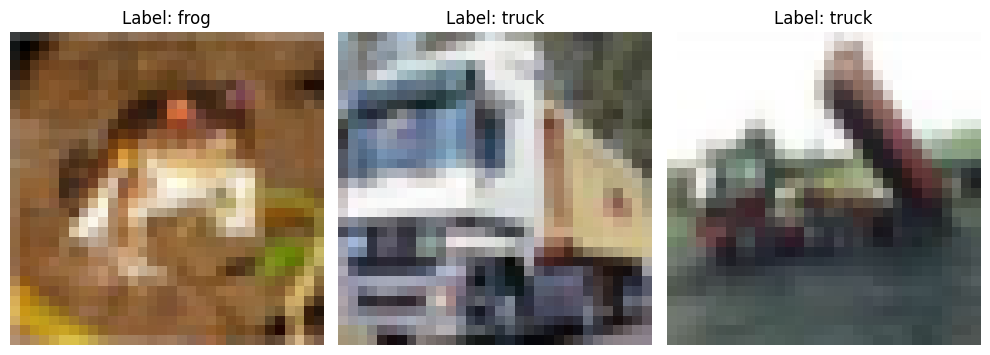

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("原始訓練資料形狀:", x_train.shape)
print("原始訓練標籤形狀:", y_train.shape)
print("原始測試資料形狀:", x_test.shape)
print("原始測試標籤形狀:", y_test.shape)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 將 (N, 1) 標籤轉成一維整數標籤，供顯示及混淆矩陣使用
y_train_int = y_train.reshape(-1)
y_test_int = y_test.reshape(-1)

# 分類模型使用 one-hot 標籤
y_train_cat = keras.utils.to_categorical(y_train_int, 10)
y_test_cat = keras.utils.to_categorical(y_test_int, 10)

print("\n正規化後訓練資料形狀:", x_train.shape)
print("訓練標籤 one-hot 形狀:", y_train_cat.shape)
print("正規化後測試資料形狀:", x_test.shape)
print("測試標籤 one-hot 形狀:", y_test_cat.shape)
print("像素值範圍:", x_train.min(), "到", x_train.max())

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(f"Label: {class_names[y_train_int[i]]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [3]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    # 第 01 層：Conv2D，(3×3×3+1)×32 = 896
    layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv_01"),
    # 第 02 層：Dropout，不含可訓練參數
    layers.Dropout(0.3, name="dropout_02"),
    # 第 03 層：Conv2D，(3×3×32+1)×32 = 9,248
    layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv_03"),
    # 第 04 層：MaxPooling，不含可訓練參數
    layers.MaxPooling2D((2, 2), name="pool_04"),

    # 第 05 層：Conv2D，(3×3×32+1)×64 = 18,496
    layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv_05"),
    # 第 06 層：Dropout，不含可訓練參數
    layers.Dropout(0.3, name="dropout_06"),
    # 第 07 層：Conv2D，(3×3×64+1)×64 = 36,928
    layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv_07"),
    # 第 08 層：MaxPooling，不含可訓練參數
    layers.MaxPooling2D((2, 2), name="pool_08"),

    # 第 09 層：Conv2D，(3×3×64+1)×128 = 73,856
    layers.Conv2D(128, (3, 3), activation="relu", padding="same", name="conv_09"),
    # 第 10 層：Dropout，不含可訓練參數
    layers.Dropout(0.3, name="dropout_10"),
    # 第 11 層：Conv2D，(3×3×128+1)×128 = 147,584
    layers.Conv2D(128, (3, 3), activation="relu", padding="same", name="conv_11"),
    # 第 12 層：MaxPooling，不含可訓練參數
    layers.MaxPooling2D((2, 2), name="pool_12"),

    # 第 13 層：Flatten；32×32 經三次 2×2 pooling 成 4×4，故輸出 4×4×128=2,048
    layers.Flatten(name="flatten_13"),
    # 第 14 層：Dropout，不含可訓練參數
    layers.Dropout(0.3, name="dropout_14"),
    # 第 15 層：Dense，(2048+1)×2500 = 5,122,500
    layers.Dense(2500, activation="relu", name="dense_15"),
    # 第 16 層：Dropout，不含可訓練參數
    layers.Dropout(0.3, name="dropout_16"),
    # 第 17 層：Dense，(2500+1)×1500 = 3,751,500
    layers.Dense(1500, activation="relu", name="dense_17"),
    # 第 18 層：Dropout，不含可訓練參數
    layers.Dropout(0.3, name="dropout_18"),
    # 第 19 層：Dense，(1500+1)×10 = 15,010
    layers.Dense(10, activation="softmax", name="output_19")
], name="cifar10_hw4_3_cnn")

model.summary()
print("\n逐層 Output Shape / Parameters：")
for i, layer in enumerate(model.layers, start=1):
    batch_size = 128

print("各層 Batch Output Shape 與參數量：")

for i, layer in enumerate(model.layers, start=1):
    batch_output_shape = (batch_size,) + tuple(layer.output.shape[1:])

    print(
        f"第 {i:02d} 層 {layer.name:15s} "
        f"batch_output_shape={batch_output_shape}, "
        f"params={layer.count_params():,}"
    )

print("\n參數計算重點：")
print("卷積層參數=(Kernel 高×Kernel 寬×輸入通道數+1)×Filter 數")
print("Flatten 輸出：4×4×128 =", 4*4*128)
print("第 15 層：(2048+1)×2500 =", (2048+1)*2500)
print("第 17 層：(2500+1)×1500 =", (2500+1)*1500)
print("第 19 層：(1500+1)×10 =", (1500+1)*10)
print("Dropout、MaxPooling、Flatten 均沒有可訓練參數。")


Model: "cifar10_hw4_3_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_01 (Conv2D)                │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_02 (Dropout)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_03 (Conv2D)                │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_04 (MaxPooling2D)          │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_05 (Conv2D)                │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_06 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_07 (Conv2D)                │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_08 (MaxPooling2D)          │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_09 (Conv2D)                │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_11 (Conv2D)                │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_12 (MaxPooling2D)          │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_13 (Flatten)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 2500)           │     5,122,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 2500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1500)           │     3,751,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_19 (Dense)               │ (None, 10)             │        15,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,176,018 (35.00 MB)

 Trainable params: 9,176,018 (35.00 MB)

 Non-trainable params: 0 (0.00 B)


逐層 Output Shape / Parameters：
各層 Batch Output Shape 與參數量：
第 01 層 conv_01         batch_output_shape=(128, 32, 32, 32), params=896
第 02 層 dropout_02      batch_output_shape=(128, 32, 32, 32), params=0
第 03 層 conv_03         batch_output_shape=(128, 32, 32, 32), params=9,248
第 04 層 pool_04         batch_output_shape=(128, 16, 16, 32), params=0
第 05 層 conv_05         batch_output_shape=(128, 16, 16, 64), params=18,496
第 06 層 dropout_06      batch_output_shape=(128, 16, 16, 64), params=0
第 07 層 conv_07         batch_output_shape=(128, 16, 16, 64), params=36,928
第 08 層 pool_08         batch_output_shape=(128, 8, 8, 64), params=0
第 09 層 conv_09         batch_output_shape=(128, 8, 8, 128), params=73,856
第 10 層 dropout_10      batch_output_shape=(128, 8, 8, 128), params=0
第 11 層 conv_11         batch_output_shape=(128, 8, 8, 128), params=147,584
第 12 層 pool_12         batch_output_shape=(128, 4, 4, 128), params=0
第 13 層 flatten_13      batch_output_shape=(128, 2048), params=0
第 14 層 dropout_1

In [4]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

EPOCHS = 50
BATCH_SIZE = 128

# 每批輸入形狀為 (128, 32, 32, 3)，最後一批可能少於 128 張
print("批次訓練 Input Shape:", (BATCH_SIZE, 32, 32, 3))
print("每層 Output Shape / Parameters 請以上方 model.summary() 為準。")

history = model.fit(
    x_train, y_train_cat,
    validation_split=0.20,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=1
)


批次訓練 Input Shape: (128, 32, 32, 3)
每層 Output Shape / Parameters 請以上方 model.summary() 為準。
Epoch 1/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 378s 1s/step - accuracy: 0.3075 - loss: 1.8403 - val_accuracy: 0.4627 - val_loss: 1.4935
Epoch 2/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 379s 1s/step - accuracy: 0.4899 - loss: 1.3903 - val_accuracy: 0.5355 - val_loss: 1.3011
Epoch 3/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 371s 1s/step - accuracy: 0.5744 - loss: 1.1854 - val_accuracy: 0.6248 - val_loss: 1.0555
Epoch 4/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 378s 1s/step - accuracy: 0.6191 - loss: 1.0612 - val_accuracy: 0.6652 - val_loss: 0.9632
Epoch 5/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 373s 1s/step - accuracy: 0.6562 - loss: 0.9641 - val_accuracy: 0.6752 - val_loss: 0.9285
Epoch 6/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 373s 1s/step - accuracy: 0.6810 - loss: 0.8971 - val_accuracy: 0.6990 - val_loss: 0.8610
Epoch 7/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 383s 1s/step - accuracy: 0.7070 - loss: 0.8280 - val_accuracy: 0.7209 - val_loss: 0.7999
Epoch 8/

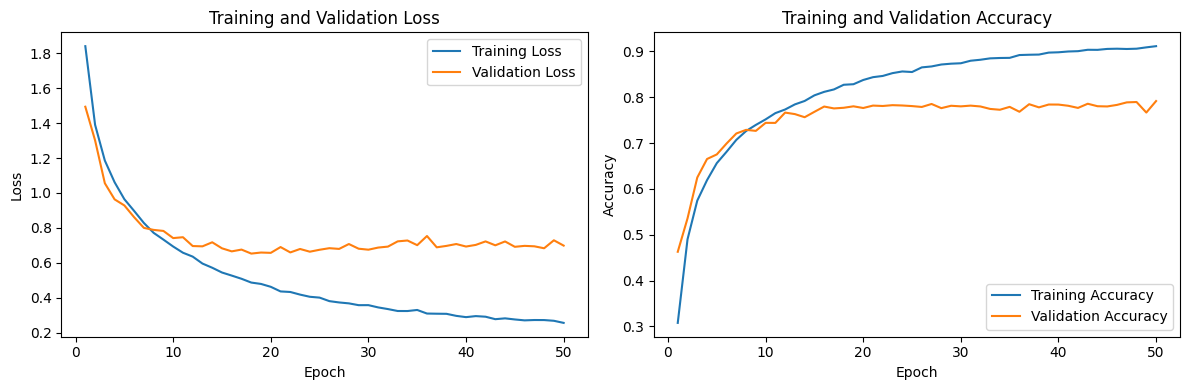

In [5]:
epochs_range = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["loss"], label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [6]:
test_loss, test_accuracy = model.evaluate(x_test, y_test_cat, verbose=1)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")


313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 77ms/step - accuracy: 0.7838 - loss: 0.7321
Test Loss: 0.7321
Test Accuracy: 0.7838 (78.38%)


79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 252ms/step


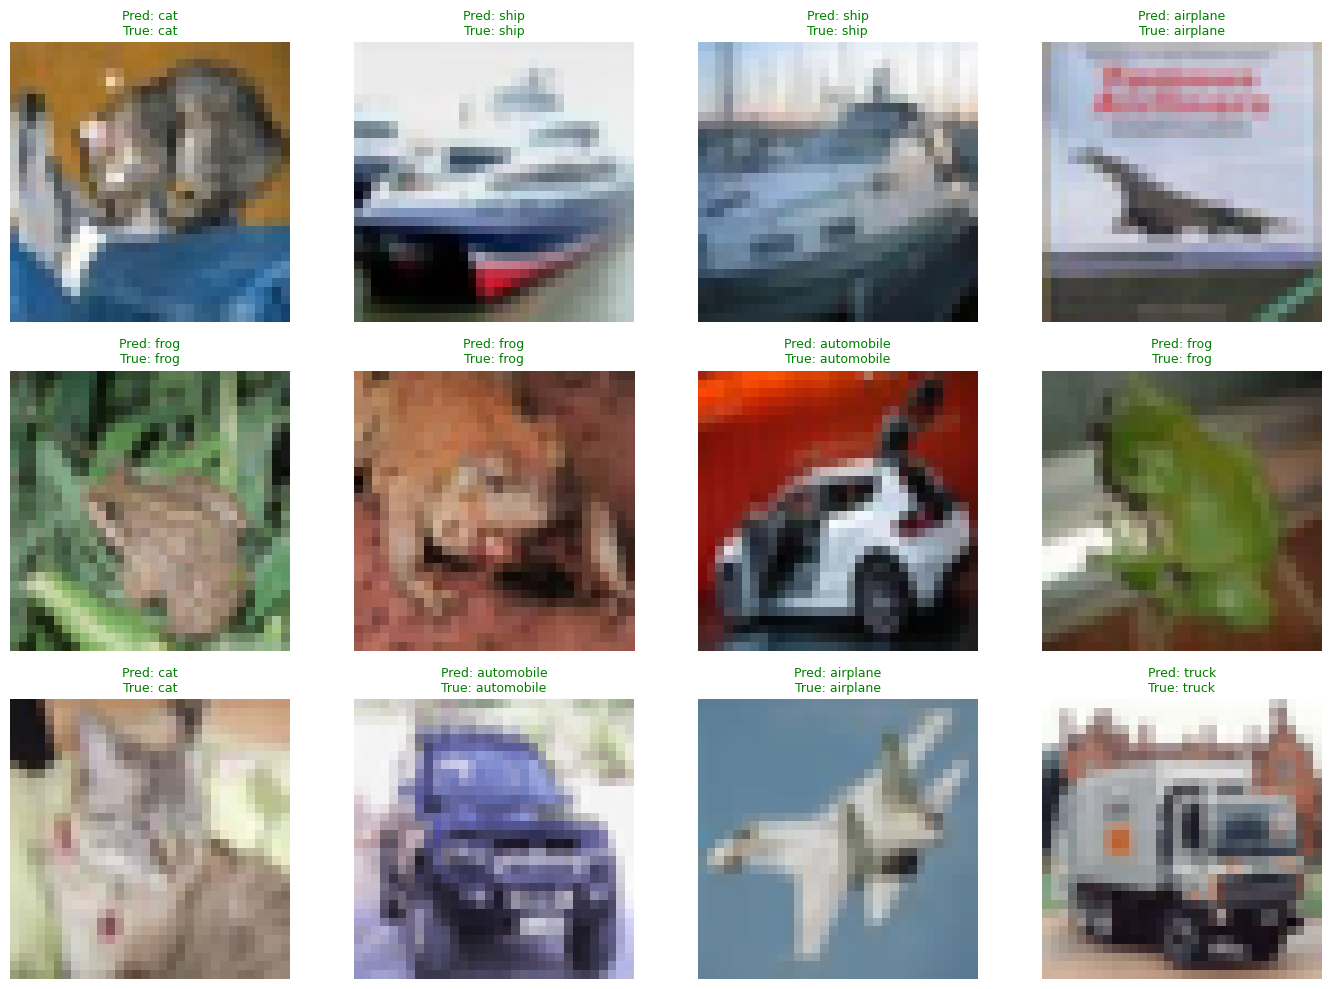

In [7]:
y_prob = model.predict(x_test, batch_size=128, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

show_n = 12
plt.figure(figsize=(14, 10))
for i in range(show_n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i])
    pred_name = class_names[y_pred[i]]
    true_name = class_names[y_test_int[i]]
    color = "green" if y_pred[i] == y_test_int[i] else "red"
    plt.title(f"Pred: {pred_name}\nTrue: {true_name}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()


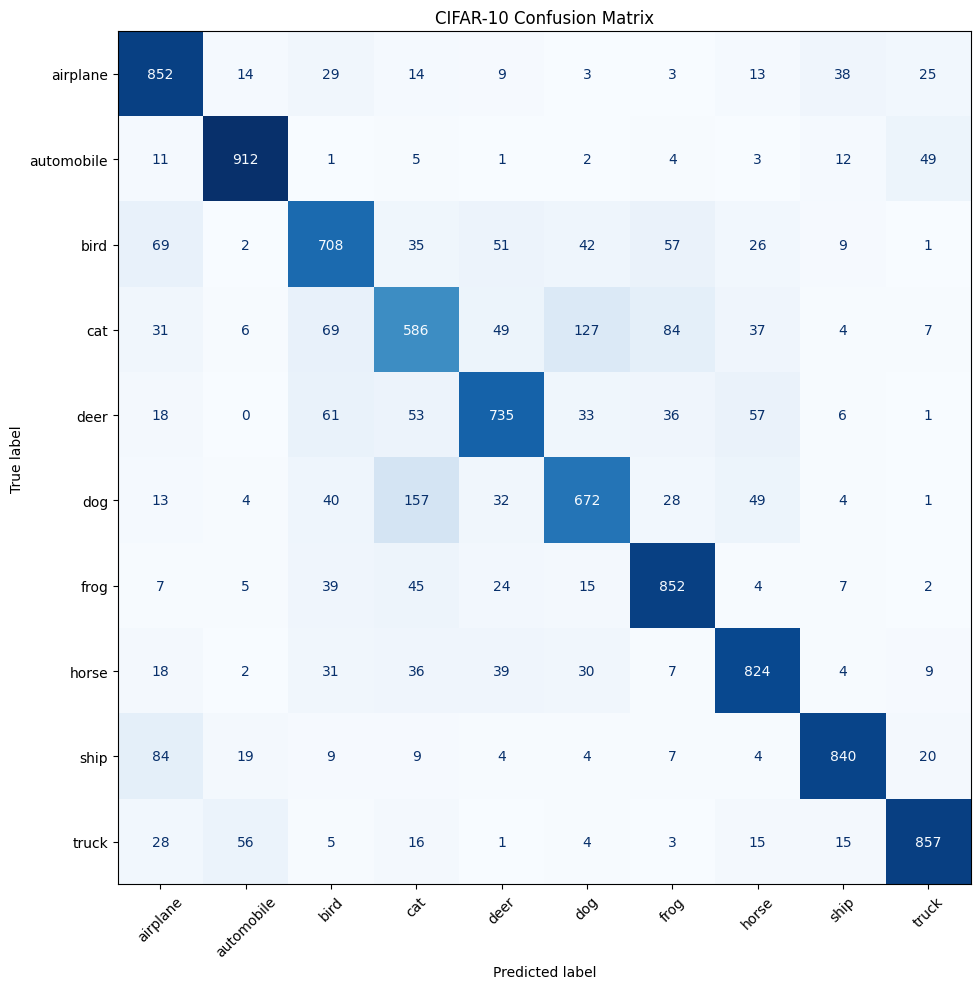

              precision    recall  f1-score   support

    airplane       0.75      0.85      0.80      1000
  automobile       0.89      0.91      0.90      1000
        bird       0.71      0.71      0.71      1000
         cat       0.61      0.59      0.60      1000
        deer       0.78      0.73      0.76      1000
         dog       0.72      0.67      0.70      1000
        frog       0.79      0.85      0.82      1000
       horse       0.80      0.82      0.81      1000
        ship       0.89      0.84      0.87      1000
       truck       0.88      0.86      0.87      1000

    accuracy                           0.78     10000
   macro avg       0.78      0.78      0.78     10000
weighted avg       0.78      0.78      0.78     10000



In [8]:
cm = confusion_matrix(y_test_int, y_pred)
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_test_int, y_pred, target_names=class_names))


In [10]:
from google.colab import drive
import os

# 掛載 Google Drive
drive.mount('/content/drive')

# 建立模型存放資料夾
model_dir = '/content/drive/MyDrive/2026_DL_hws'
os.makedirs(model_dir, exist_ok=True)

# 儲存模型
model.save(model_dir + '/hw4-3_model.keras')

print("HW4-2 模型已儲存到 Google Drive！")

Mounted at /content/drive
HW4-2 模型已儲存到 Google Drive！


In [11]:
from google.colab import drive
drive.mount('/content/drive')

previous_path = '/content/drive/MyDrive/2026_DL_hws/hw4-2_model.keras'

previous_model = keras.models.load_model(previous_path)

prev_loss, prev_acc = previous_model.evaluate(
    x_test, y_test_cat, verbose=0
)

print(f"HW4-2 Test Accuracy: {prev_acc:.4f}")
print(f"HW4-3 Test Accuracy: {test_accuracy:.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
HW4-2 Test Accuracy: 0.7066
HW4-3 Test Accuracy: 0.7838
